# dataeuropa: worked examples (Python)

Three tasks with [data.europa.eu](https://data.europa.eu), the European open data portal, from a
search to a result: air quality in Lisbon from a CSV file, who publishes air-quality data and in
what formats, and the boundaries of Gelsenkirchen from a feature service.

The same examples, with explanations, are in the [Python documentation](https://randsley.github.io/dataeuropa/python/examples/); notebooks for the
other two languages are next to this one. Install: `pip install "dataeuropa[pandas,geo]"` (and matplotlib for the map).

The outputs were stored when the notebook was last run (the date is printed below each data
source). The portal changes all the time, so counts and search results will differ when you run it.

In [1]:
from datetime import date
import dataeuropa as de

print("dataeuropa", de.__version__)
retrieved = date.today().isoformat()

dataeuropa 0.1.1


## 1. Air quality in Lisbon: from a search to a summary table

Find air-quality data from Portugal that comes as CSV. Quotes make the search match the phrase,
not the separate words.

In [2]:
hits = de.search_datasets('"air quality"', country="pt", format="CSV")
hits[["id", "title", "publisher"]]

,id,title,publisher
0,67a5e928a3ee7360b61cd5e4,"Sensing: Monthly reports with Air Quality, Sou...",Câmara Municipal de Oeiras
1,6689f1686e4bd9bc98ed011b,Monitoring of Environmental Parameters of the ...,Município de Lisboa


The Lisbon dataset has one file per period: `QA` files hold air quality, `ME` files weather. List
the files only (no services or web pages), then read the first quarter of 2024. The file's
checksum is checked when the portal has one.

In [3]:
files = de.distributions("6689f1686e4bd9bc98ed011b", files_only=True)
files[["title", "format"]]

,title,format
0,ME_2024_S1,CSV
1,QA_2023,ZIP
2,ME_2022,ZIP
3,QA_2022,ZIP
4,ME_2021_S2,CSV
5,QA_2024_Q1,CSV
6,ME_2023,ZIP
7,Traffic,CSV
8,Noise,CSV
9,Metadata,PDF


In [4]:
row = files[files["title"] == "QA_2024_Q1"].iloc[0]
qa = de.load_distribution(row)
qa[["DTM_LOCAL", "PARAMETRO", "LOCAL", "UNIDADE", "VALOR"]].head(3)

,DTM_LOCAL,PARAMETRO,LOCAL,UNIDADE,VALOR
0,2024-01-05 19:00:00.0,PM25,Calçada da Ajuda,µg/m3,6.0
1,2024-01-06 03:00:00.0,PM25,Calçada da Ajuda,µg/m3,5.0
2,2024-01-06 04:00:00.0,PM25,Calçada da Ajuda,µg/m3,3.0


The file is in long format: one row per reading, with the pollutant in `PARAMETRO`. `-99` marks a
missing reading. Some stations have only a few readings, so count them too and keep the stations
with at least 300 before comparing NO₂ means.

In [5]:
no2 = qa[(qa["PARAMETRO"] == "NO2") & (qa["VALOR"] >= 0)]
by_station = no2.groupby("LOCAL")["VALOR"].agg(["mean", "count"])
by_station[by_station["count"] >= 300].nlargest(5, "mean").round(1)

,mean,count
LOCAL,,
Avenida António Augusto de Aguiar,111.9,356
Campo de Ourique,95.3,356
Praça São Francisco de Assis,93.9,356
Rua Morais Soares,92.0,356
Estrada de Monsanto,78.0,356


In [6]:
lisbon = de.get_dataset("6689f1686e4bd9bc98ed011b")
print(f"Source:    {lisbon['title']}")
print(f"Publisher: {lisbon['publisher']}")
print(f"Portal:    {lisbon['portal_url']}")
print(f"File:      {row['title']} (first quarter of 2024), {row['url']}")
print(f"Licence:   {row['license'] or 'not stated on the portal'}")
print(f"Retrieved: {retrieved}")

Source:    Monitoring of Environmental Parameters of the City of Lisbon - Historical 15/07/2021 to 15/01/2024
Publisher: Município de Lisboa
Portal:    https://data.europa.eu/data/datasets/6689f1686e4bd9bc98ed011b
File:      QA_2024_Q1 (first quarter of 2024), https://dados.cm-lisboa.pt/dataset/9954113c-3f2c-44ea-a59c-5b989da83156/resource/c580a5a0-d2fc-458c-921b-9a08dbc2893c/download/qa2024q1.csv
Licence:   https://creativecommons.org/licenses/by/4.0/
Retrieved: 2026-11-28


## 2. Who publishes air-quality data, and in what formats

Counts and facets need no records, so they are fast. `EUROPE` is the value for datasets about
Europe as a whole. A dataset with several formats counts once for each.

In [7]:
de.count('"air quality"')

3582

In [8]:
de.facet_values("country", '"air quality"', top=8)

,id,label,count
0,EUROPE,Europe,621
1,de,Germany,539
2,fr,France,449
3,gb,United Kingdom,373
4,es,Spain,347
5,it,Italy,247
6,ro,Romania,189
7,bg,Bulgaria,147


In [9]:
de.facet_values("format", '"air quality"', top=6)

,id,label,count
0,CSV,CSV,862
1,JSON,JSON,536
2,XML,XML,391
3,WMS_SRVC,WMS,244
4,ZIP,ZIP,166
5,HTML,HTML,147


In [10]:
print(f"Source: data.europa.eu Search API (counts and facets), retrieved {retrieved}")

Source: data.europa.eu Search API (counts and facets), retrieved 2026-11-28


## 3. Boundaries of Gelsenkirchen from a feature service

The city of Gelsenkirchen publishes its administrative boundaries as a GeoServer service, which the
portal lists as OGC API Features and as WFS. This needs the `geo` extra.

The OGC API Features entry points to one collection, the cadastral districts, in ETRS89 / UTM zone
32N (EPSG:25832, metres), so areas can be computed directly. The WFS entry is the whole service,
with 22 layers; pick the city quarters by name (the namespace prefix can be left out) and reproject
them to longitude and latitude.

In [11]:
dists = de.distributions("eac1e504-9d63-4670-95b3-3ef04e22aa6e~~1")
dists[["format", "kind"]]

,format,kind
0,OGCFEAT,service
1,JSON,file
2,WFS_SRVC,service


In [12]:
districts = de.load_geodata(dists[dists["format"] == "OGCFEAT"].iloc[0])
districts["area_km2"] = (districts.area / 1e6).round(2)
districts[["gemarkung_name", "area_km2"]].sort_values("area_km2", ascending=False).head(3)

,gemarkung_name,area_km2
5,Buer,61.29
4,Bismarck,10.08
9,Heßler,6.88


18 city quarters


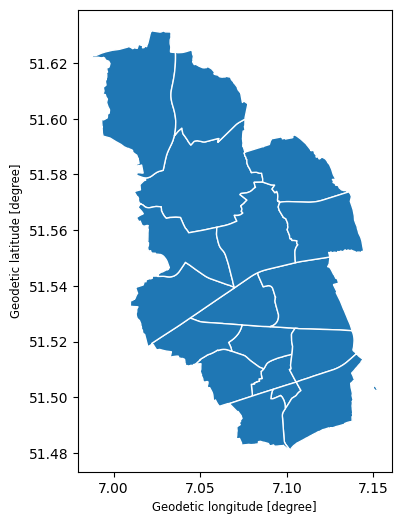

In [13]:
quarters = de.load_geodata(dists[dists["format"] == "WFS_SRVC"].iloc[0], layer="stadtteil", crs="EPSG:4326")
print(len(quarters), "city quarters")
quarters.plot(edgecolor="white", figsize=(6, 6));

In [14]:
gk = de.get_dataset("eac1e504-9d63-4670-95b3-3ef04e22aa6e~~1")
licences = sorted(set(dists["license"].dropna()))
print(f"Source:    {gk['title']} (catalogue {gk['catalog']})")
print(f"Publisher: {gk['publisher'] or 'not named in the record; contact point ' + gk['raw']['contact_point'][0]['url'][0]}")
print(f"Portal:    {gk['portal_url']}")
print(f"Licence:   {', '.join(licences) or 'not stated on the portal (rights: no access restrictions)'}")
print(f"Retrieved: {retrieved}")

Source:    Municipalities of Gelsenkirchen (catalogue gdi-de)
Publisher: not named in the record; contact point https://www.gelsenkirchen.de
Portal:    https://data.europa.eu/data/datasets/eac1e504-9d63-4670-95b3-3ef04e22aa6e~~1
Licence:   not stated on the portal (rights: no access restrictions)
Retrieved: 2026-11-28
